In [1]:
# Import libraries for data analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Online Retail dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx"

df = pd.read_excel(url)

# Display the first five rows
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
# Check the dataset size
print("Dataset shape:", df.shape)

# Check column names and data types
print("\nDataset information:")
df.info()

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Generate descriptive statistics
print("\nDescriptive statistics:")
display(df.describe())

Dataset shape: (541909, 8)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Descriptive statistics:


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [3]:
# 1. Check the number of cancelled invoices
cancelled = df['InvoiceNo'].astype(str).str.startswith('C')
print("Cancelled invoices:", cancelled.sum())

# 2. Check negative quantities
print("Rows with negative quantities:", (df['Quantity'] < 0).sum())

# 3. Check zero or negative prices
print("Rows with zero prices:", (df['UnitPrice'] == 0).sum())
print("Rows with negative prices:", (df['UnitPrice'] < 0).sum())

# 4. Display examples of negative quantities
display(df[df['Quantity'] < 0].head(10))

# 5. Display examples of negative prices
display(df[df['UnitPrice'] < 0].head(10))

Cancelled invoices: 9288
Rows with negative quantities: 10624
Rows with zero prices: 2515
Rows with negative prices: 2


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [4]:
# Create a copy of the original dataset
sales = df.copy()

# Remove rows without a product description
sales = sales.dropna(subset=['Description'])

# Identify cancelled invoices
cancelled = sales['InvoiceNo'].astype(str).str.startswith('C')

# Keep non-cancelled transactions with positive quantities and prices
sales = sales[
    (~cancelled) &
    (sales['Quantity'] > 0) &
    (sales['UnitPrice'] > 0)
].copy()

# Calculate revenue for each transaction line
sales['Revenue'] = sales['Quantity'] * sales['UnitPrice']

# Display the results
print("Original rows:", len(df))
print("Cleaned sales rows:", len(sales))
print("Rows removed:", len(df) - len(sales))

print("\nTotal sales revenue: £", round(sales['Revenue'].sum(), 2))

display(sales.head())

Original rows: 541909
Cleaned sales rows: 530104
Rows removed: 11805

Total sales revenue: £ 10666684.54


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [5]:
# Find the top 10 products by total revenue

top_products = (
    sales.groupby('Description')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# Display the results
print("Top 10 Products by Revenue:")
display(top_products)

Top 10 Products by Revenue:


,Revenue
Description,
DOTCOM POSTAGE,206248.77
REGENCY CAKESTAND 3 TIER,174484.74
"PAPER CRAFT , LITTLE BIRDIE",168469.60
WHITE HANGING HEART T-LIGHT HOLDER,106292.77
PARTY BUNTING,99504.33
JUMBO BAG RED RETROSPOT,94340.05
MEDIUM CERAMIC TOP STORAGE JAR,81700.92
Manual,78112.82
POSTAGE,78101.88


,Revenue
YearMonth,
2010-12,823746.140
2011-01,691364.560
2011-02,523631.890
2011-03,717639.360
2011-04,537808.621
2011-05,770536.020
2011-06,761739.900
2011-07,719221.191
2011-08,759138.380


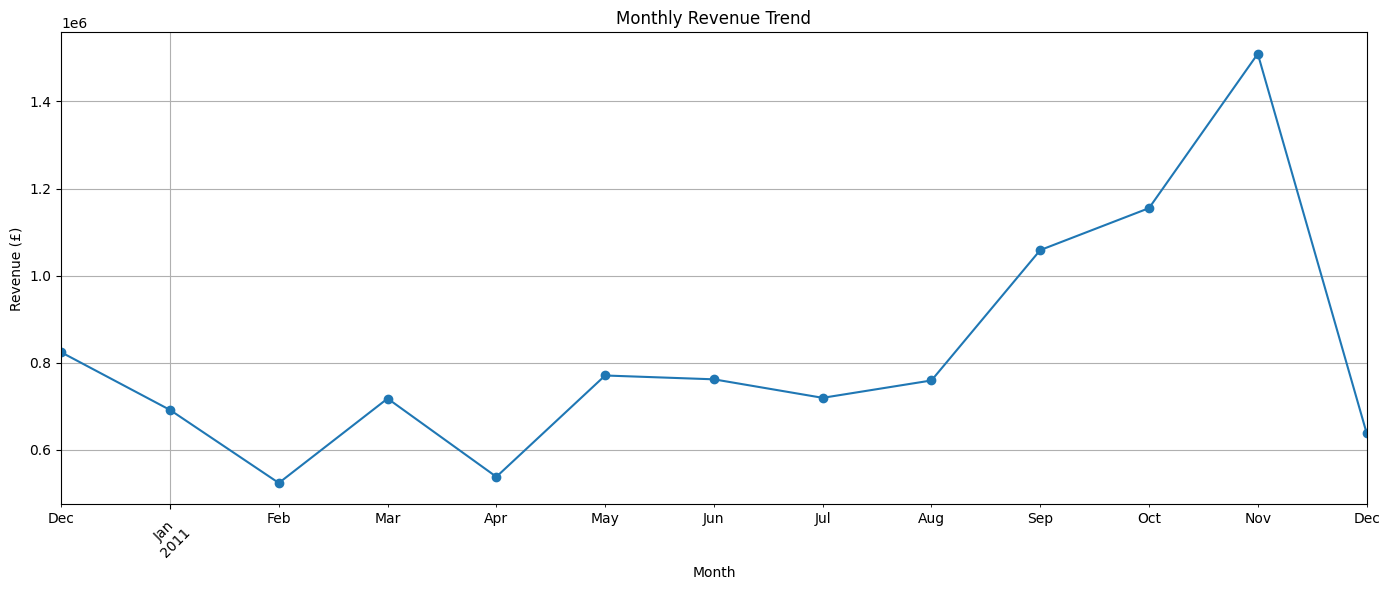

In [6]:
# Step 5: Monthly Sales Analysis

# Extract year and month from invoice date
sales['YearMonth'] = sales['InvoiceDate'].dt.to_period('M')

# Calculate monthly revenue
monthly_sales = sales.groupby('YearMonth')['Revenue'].sum()

# Display monthly revenue
display(monthly_sales)

# Visualize monthly revenue
plt.figure(figsize=(14, 6))
monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


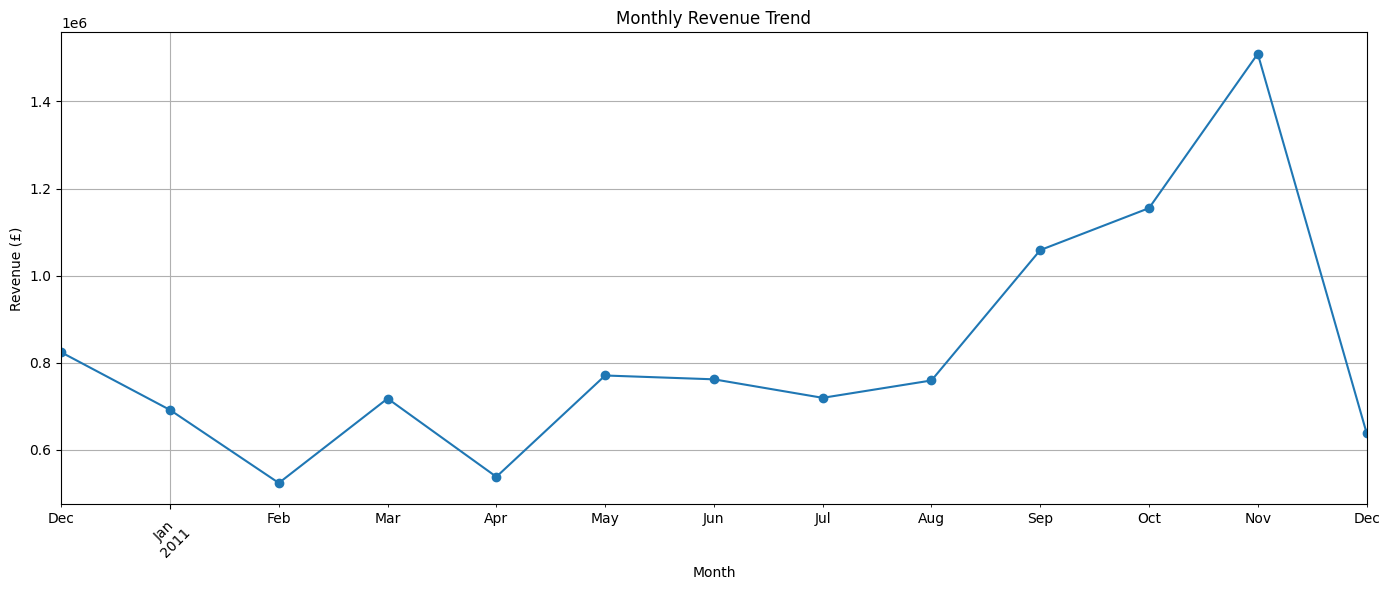

In [7]:
# Extract month and year from invoice date
sales['YearMonth'] = sales['InvoiceDate'].dt.to_period('M')

# Calculate monthly revenue
monthly_sales = sales.groupby('YearMonth')['Revenue'].sum()

# Plot monthly revenue
plt.figure(figsize=(14, 6))
monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [8]:
# Calculate total revenue by country

country_revenue = (
    sales.groupby('Country')['Revenue']
    .sum()
    .sort_values(ascending=False)
)

# Display the top 10 countries
print("Top 10 Countries by Revenue:")
display(country_revenue.head(10))

Top 10 Countries by Revenue:


,Revenue
Country,
United Kingdom,9025222.084
Netherlands,285446.340
EIRE,283453.960
Germany,228867.140
France,209715.110
Australia,138521.310
Spain,61577.110
Switzerland,57089.900
Belgium,41196.340


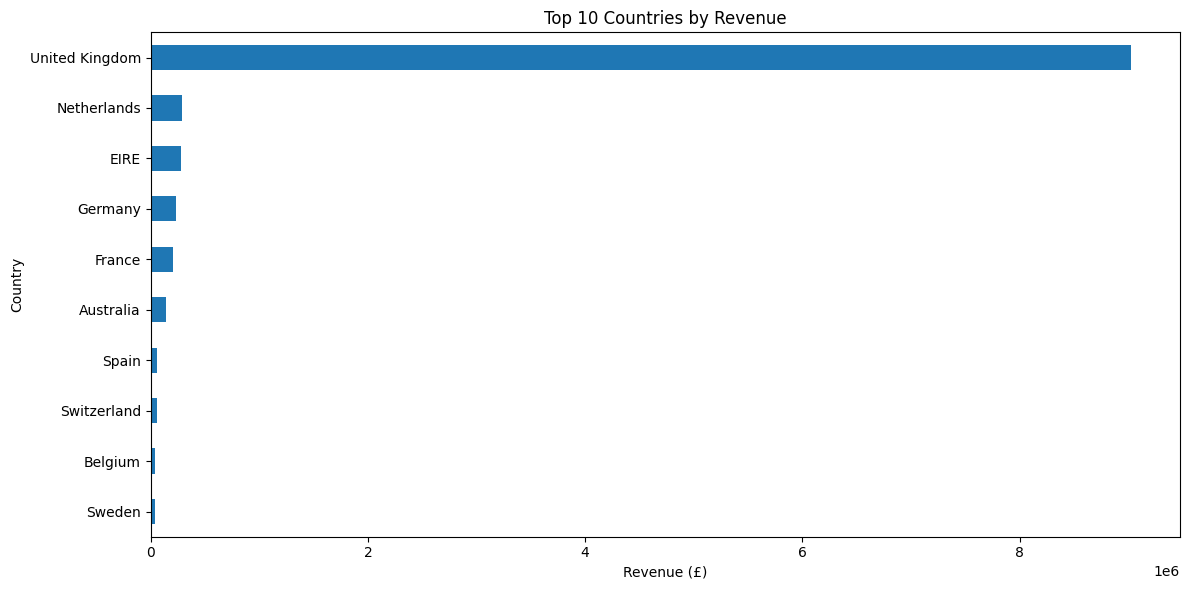

In [9]:
# Visualize the top 10 countries by revenue

top_countries = country_revenue.head(10)

plt.figure(figsize=(12, 6))

top_countries.sort_values().plot(kind='barh')

plt.title('Top 10 Countries by Revenue')
plt.xlabel('Revenue (£)')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

Monthly Sales Quantity:


,Quantity
InvoiceDate,
2010-12,359239
2011-01,387785
2011-02,283555
2011-03,377526
2011-04,308815
2011-05,395738
2011-06,389213
2011-07,401759
2011-08,421770


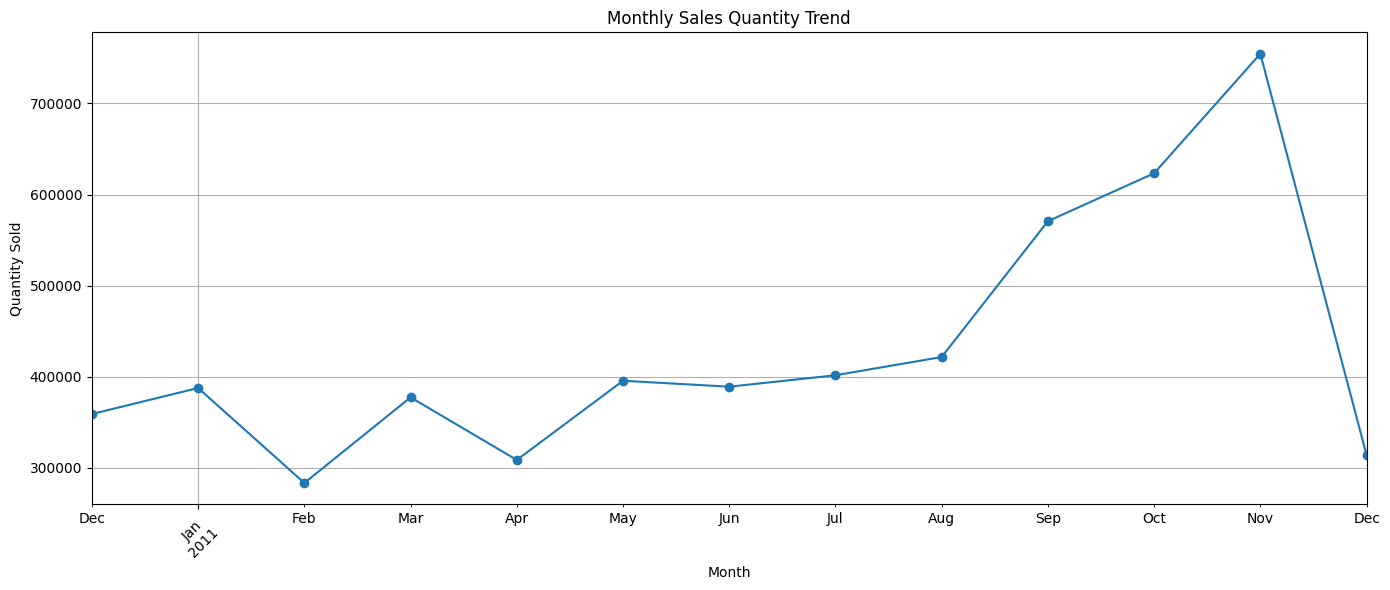

In [10]:
# Calculate total quantity sold per month

monthly_quantity = (
    sales.groupby(sales['InvoiceDate'].dt.to_period('M'))['Quantity']
    .sum()
)

# Display monthly sales quantity
print("Monthly Sales Quantity:")
display(monthly_quantity)

# Visualize monthly sales quantity
plt.figure(figsize=(14, 6))

monthly_quantity.plot(kind='line', marker='o')

plt.title('Monthly Sales Quantity Trend')
plt.xlabel('Month')
plt.ylabel('Quantity Sold')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

Top 10 Customers by Revenue:


,Revenue
CustomerID,
14646.0,280206.02
18102.0,259657.30
17450.0,194550.79
16446.0,168472.50
14911.0,143825.06
12415.0,124914.53
14156.0,117379.63
17511.0,91062.38
16029.0,81024.84


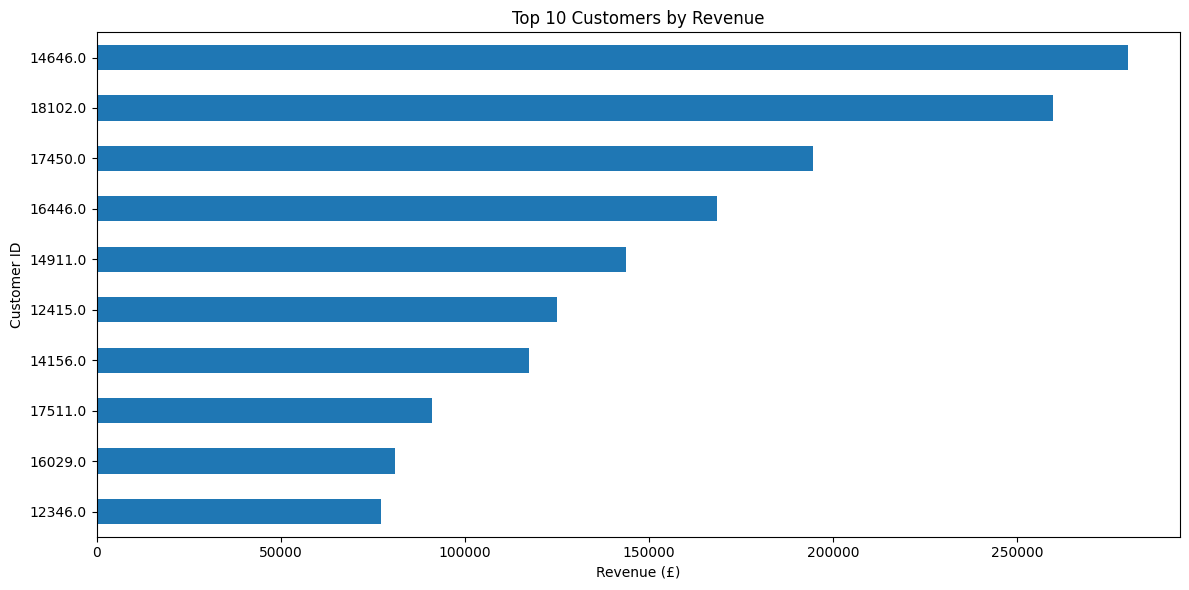

In [11]:
# Top 10 Customers by Revenue

customer_revenue = (
    sales.dropna(subset=['CustomerID'])
    .groupby('CustomerID')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Customers by Revenue:")
display(customer_revenue)

# Visualize the results
plt.figure(figsize=(12, 6))

customer_revenue.sort_values().plot(kind='barh')

plt.title('Top 10 Customers by Revenue')
plt.xlabel('Revenue (£)')
plt.ylabel('Customer ID')
plt.tight_layout()
plt.show()

In [14]:
monthly_orders = (
    sales.groupby(sales['InvoiceDate'].dt.to_period('M'))['InvoiceNo']
    .nunique()
)

print("Monthly Number of Orders:")
display(monthly_orders)

Monthly Number of Orders:


,InvoiceNo
InvoiceDate,
2010-12,1559
2011-01,1086
2011-02,1100
2011-03,1454
2011-04,1246
2011-05,1681
2011-06,1533
2011-07,1475
2011-08,1361


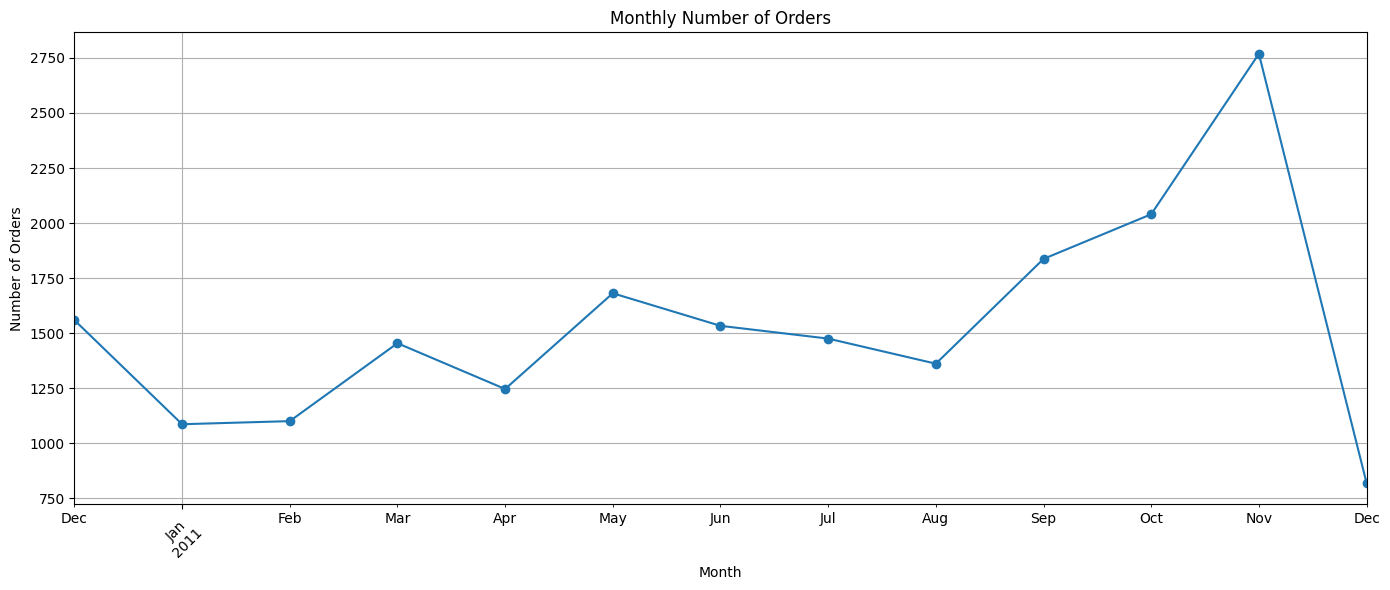

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
monthly_orders.plot(kind='line', marker='o')

plt.title('Monthly Number of Orders')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
print("========== E-COMMERCE SALES ANALYSIS SUMMARY ==========")

print(f"\nTotal Revenue: £{sales['Revenue'].sum():,.2f}")
print(f"Total Sales Transactions (Invoices): {sales['InvoiceNo'].nunique():,}")
print(f"Unique Products Sold: {sales['StockCode'].nunique():,}")
print(f"Unique Customers: {sales['CustomerID'].nunique():,}")
print(f"Countries Served: {sales['Country'].nunique():,}")

print("\nTop 5 Countries by Revenue:")
display(country_revenue.head(5))

print("\nTop 5 Products by Revenue:")
display(top_products.head(5))

print("\nTop 5 Customers by Revenue:")
display(customer_revenue.head(5))

========== E-COMMERCE SALES ANALYSIS SUMMARY ==========

Total Revenue: £10,666,684.54
Total Sales Transactions (Invoices): 19,960
Unique Products Sold: 3,922
Unique Customers: 4,338
Countries Served: 38

Top 5 Countries by Revenue:


,Revenue
Country,
United Kingdom,9025222.084
Netherlands,285446.340
EIRE,283453.960
Germany,228867.140
France,209715.110



Top 5 Products by Revenue:


,Revenue
Description,
DOTCOM POSTAGE,206248.77
REGENCY CAKESTAND 3 TIER,174484.74
"PAPER CRAFT , LITTLE BIRDIE",168469.60
WHITE HANGING HEART T-LIGHT HOLDER,106292.77
PARTY BUNTING,99504.33



Top 5 Customers by Revenue:


,Revenue
CustomerID,
14646.0,280206.02
18102.0,259657.30
17450.0,194550.79
16446.0,168472.50
14911.0,143825.06
